# 06 · Wilson loops, Wannier charge centres and Z2

The Wilson loop $W(k_y)=\prod_j U(k_{x,j},k_{x,j+1})$ of occupied states has eigenvalues
$e^{-2\pi i \bar x_n(k_y)}$: the hybrid Wannier charge centres (WCC). Their winding gives
the Chern number; Kramers partner switching gives Z2.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline

## 1. WCC of a Chern insulator: winding

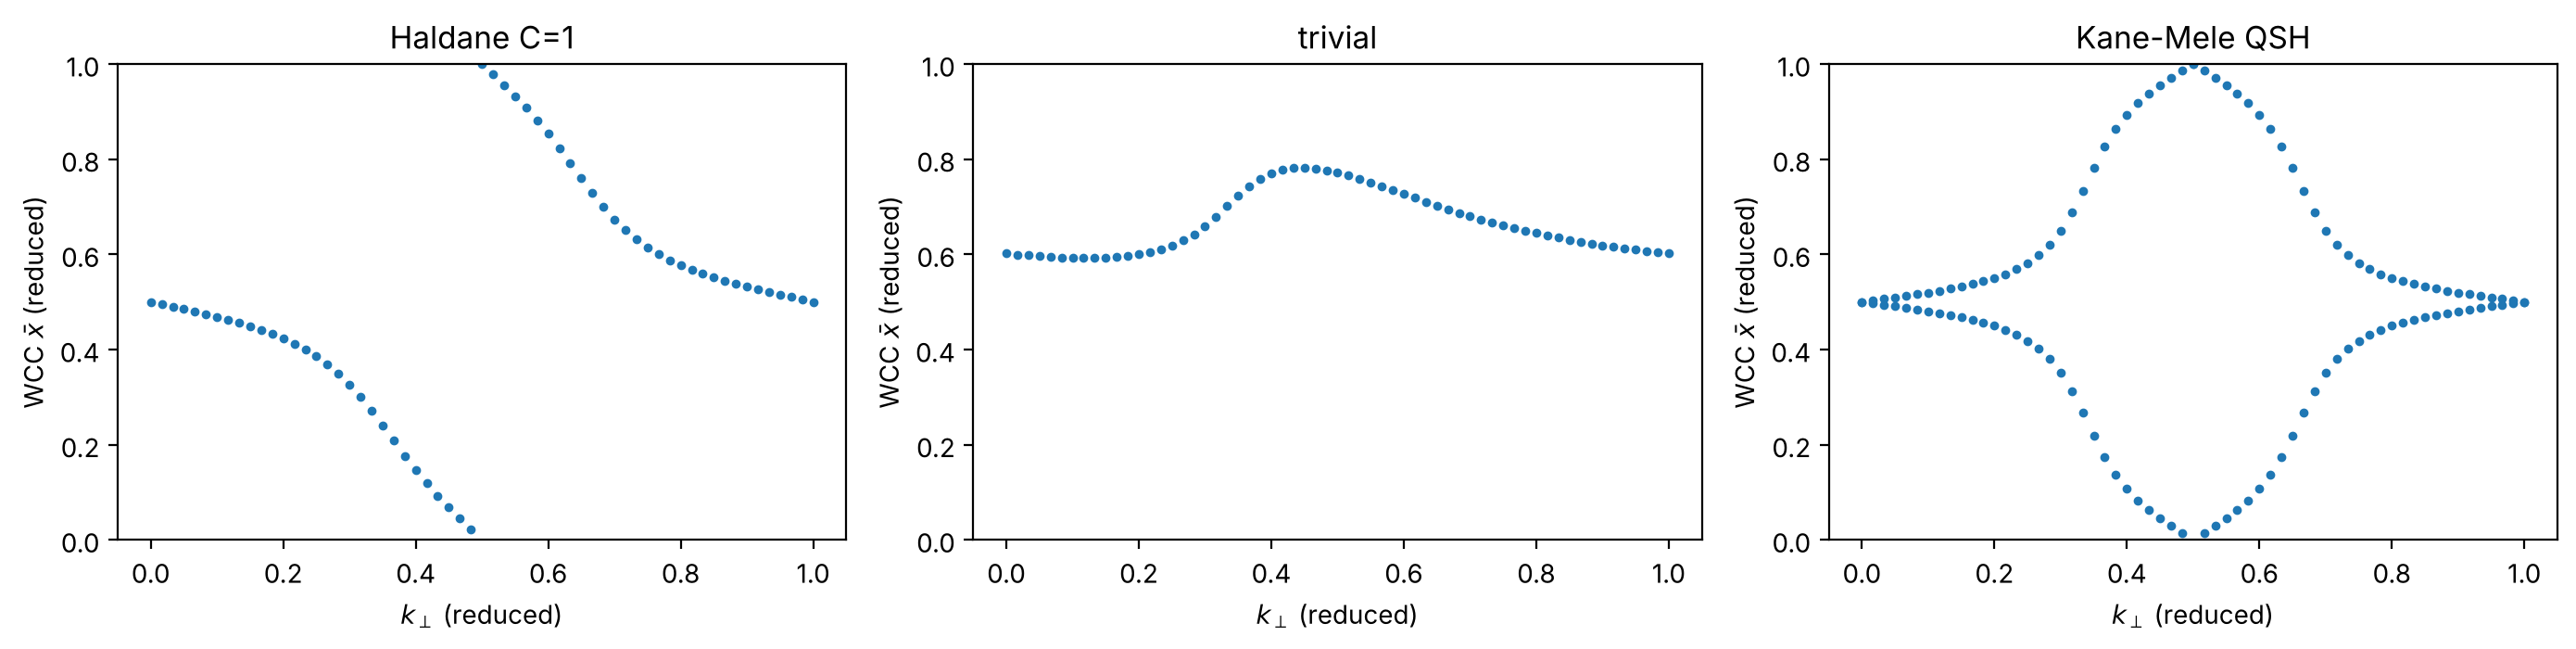

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (m, occ, t) in zip(axes, [(M.haldane(), 1, "Haldane C=1"), (M.haldane(M=1), 1, "trivial"),
                                  (M.kane_mele(), 2, "Kane-Mele QSH")]):
    ks, wcc = hf.wilson_loop(m, occ, direction=0, nscan=61)
    hf.plot_wcc(wcc, ax=ax, kperp=ks, title=t)
plt.tight_layout()

## 2. Z2 by the largest-gap method

In [3]:
for lv in [0.0, 0.2, 0.3, 0.4, 0.6]:
    print(f"Kane-Mele lv = {lv:.1f}: Z2 = {hf.z2_invariant(M.kane_mele(lv=lv), 2)}   (critical 3√3·λso = {3*np.sqrt(3)*0.06:.3f})")

Kane-Mele lv = 0.0: Z2 = 1   (critical 3√3·λso = 0.312)


Kane-Mele lv = 0.2: Z2 = 1   (critical 3√3·λso = 0.312)


Kane-Mele lv = 0.3: Z2 = 1   (critical 3√3·λso = 0.312)


Kane-Mele lv = 0.4: Z2 = 0   (critical 3√3·λso = 0.312)


Kane-Mele lv = 0.6: Z2 = 0   (critical 3√3·λso = 0.312)


In [4]:
print("with Rashba 0.05:", hf.z2_invariant(M.kane_mele(lr=0.05), 2))
for Mv in [-1, 1, 3, 5, 9]:
    print(f"BHZ M/B = {Mv}: Z2 = {hf.z2_invariant(M.bhz(M=Mv), 2)}")

with Rashba 0.05: 1


BHZ M/B = -1: Z2 = 0


BHZ M/B = 1: Z2 = 1
BHZ M/B = 3: Z2 = 1


BHZ M/B = 5: Z2 = 1


BHZ M/B = 9: Z2 = 0


## 3. Fu-Kane parity criterion (inversion-symmetric models)

In [5]:
par = np.kron(np.diag([1, -1]), np.eye(2))      # E (s-like) even, H (p-like) odd
for Mv in [-1, 1]:
    z2, deltas = hf.fu_kane_parity(M.bhz(M=Mv), 2, par)
    print(f"BHZ M = {Mv}: Z2 = {z2}, delta_i at TRIM = {deltas}")

BHZ M = -1: Z2 = 0, delta_i at TRIM = [1, 1, 1, 1]
BHZ M = 1: Z2 = 1, delta_i at TRIM = [-1, 1, 1, 1]


## 4. 3D topological insulators: (ν0; ν1ν2ν3)

In [6]:
print("Wilson-Dirac M= 1:", hf.z2_3d(M.wilson_dirac_ti(M=1), 2, nk=30, nscan=31))
print("Wilson-Dirac M= 5:", hf.z2_3d(M.wilson_dirac_ti(M=5), 2, nk=30, nscan=31))
print("Wilson-Dirac M=-1:", hf.z2_3d(M.wilson_dirac_ti(M=-1), 2, nk=30, nscan=31))
print("FKM dt=+0.4      :", hf.z2_3d(M.diamond_fkm(dt=0.4), 2, nk=30, nscan=31))
print("FKM dt=-0.4      :", hf.z2_3d(M.diamond_fkm(dt=-0.4), 2, nk=30, nscan=31))

Wilson-Dirac M= 1: (1, 0, 0, 0)


Wilson-Dirac M= 5: (0, 1, 1, 1)


Wilson-Dirac M=-1: (0, 0, 0, 0)


FKM dt=+0.4      : (1, 1, 1, 1)
FKM dt=-0.4      : (0, 1, 1, 1)


## 5. WCC flow on the planes of a 3D TI

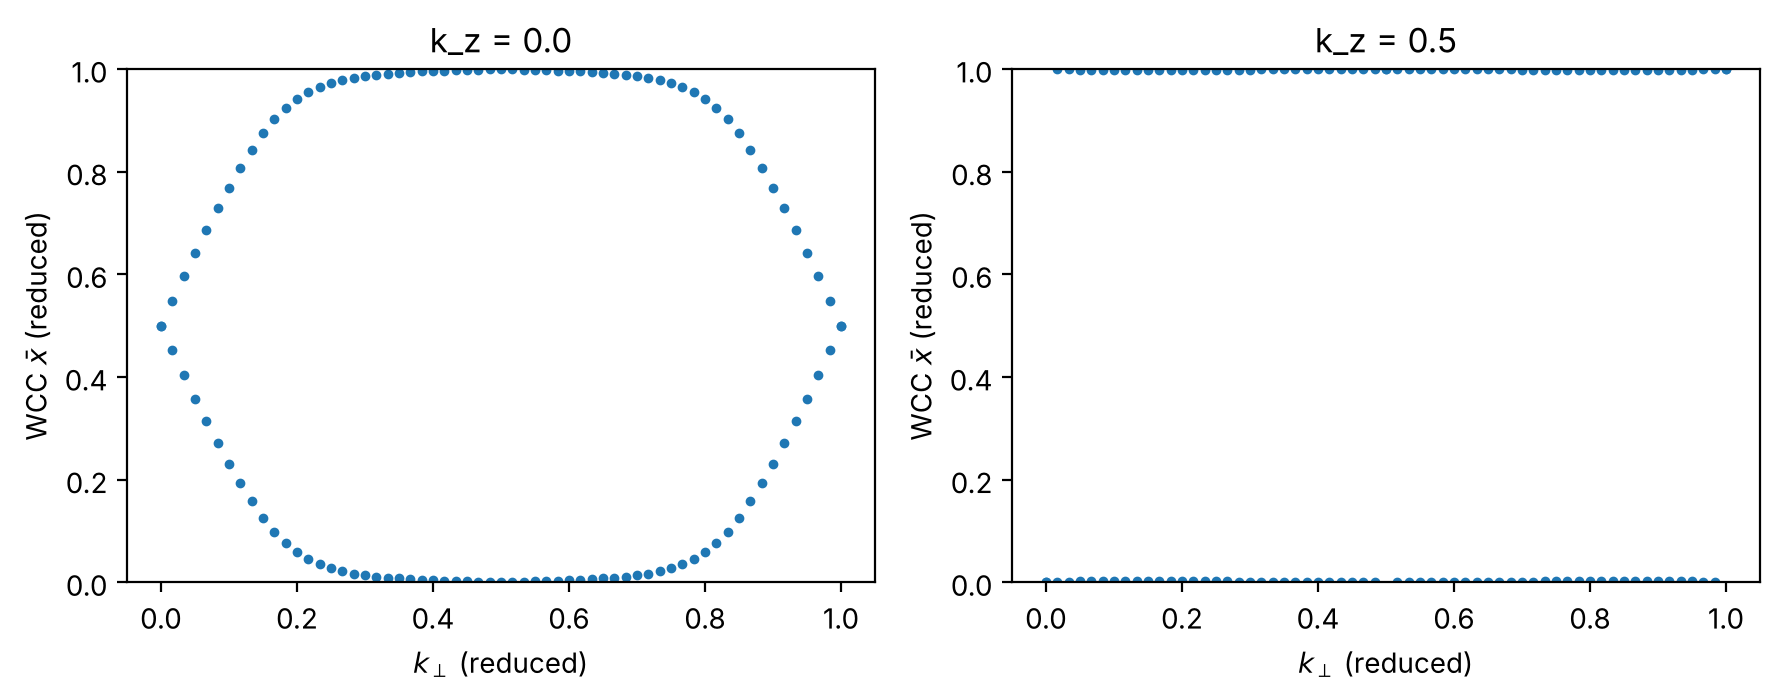

In [7]:
wd = M.wilson_dirac_ti()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, kz in zip(axes, [0.0, 0.5]):
    ks, wcc = hf.wilson_loop(wd, 2, direction=0, scan=1, fixed={2: kz}, nscan=61)
    hf.plot_wcc(wcc, ax=ax, kperp=ks, title=f"k_z = {kz}")
plt.tight_layout()

## 6. Surface Dirac cone of a 3D TI slab

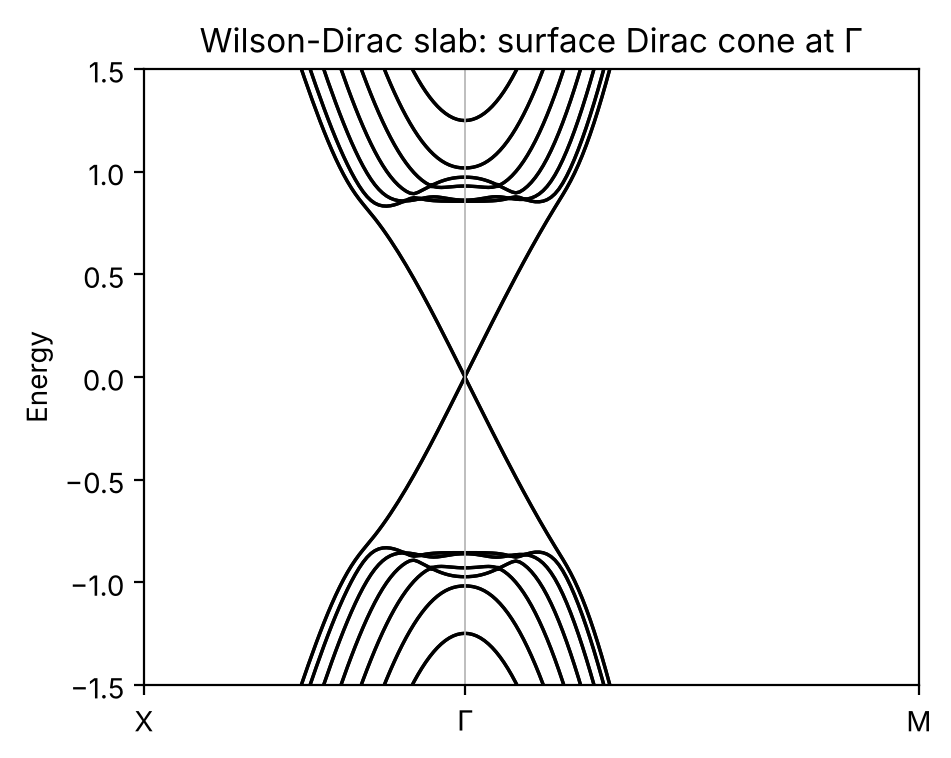

In [8]:
slab = M.wilson_dirac_ti().slab(2, 14)
slab.plot_bands(["X", "G", "M"], ylim=(-1.5, 1.5), title="Wilson-Dirac slab: surface Dirac cone at Γ");

## Exercises
1. Plot the WCC of BHZ for M = 1 and M = -1 side by side.
2. Find the Rashba strength at which the Kane-Mele bulk gap closes.
3. Build a slab of the FKM model and count the surface Dirac cones for dt > 0 and dt < 0.

---
## Quiz 06: Wilson loops and Z2

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [9]:
quiz = hf.Quiz(6)
quiz.interactive()

In [10]:
quiz.show()

=== Quiz 06: Wilson loops, Wannier charge centres and Z2 invariants ===

Q1. The eigenvalues of the Wilson loop along k_x, as a function of k_y, give
   (a) hybrid Wannier charge centres (WCC) x(k_y)
   (b) band energies
   (c) the DOS
   (d) Berry curvature

Q2. For a Chern insulator with C = 1, the WCC as a function of k_y
   (a) wind once across the unit cell
   (b) vanish
   (c) come in degenerate pairs
   (d) stay constant

Q3. In a time-reversal-invariant system, WCC at k_y = 0 and k_y = pi
   (a) are random
   (b) are Kramers degenerate in pairs
   (c) do not exist
   (d) are always zero

Q4. A nontrivial Z2 shows in the WCC flow over half the BZ as
   (a) a single flat line
   (b) Kramers partners switching (zig-zag): any line crosses an odd number of WCC
   (c) no motion
   (d) an even number of crossings

Q5. The largest-gap method of Soluyanov & Vanderbilt tracks
   (a) the band gap
   (b) the Fermi level
   (c) the midpoint of the largest gap between WCC and counts WCC that

In [11]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0